# Assignment 1 — EDA and Baseline Models
**CENG313 Data Science · Group 53**

**Competition:** [Rohlik Sales Forecasting Challenge v2](https://www.kaggle.com/competitions/rohlik-sales-forecasting-challenge-v2)

**Task:** forecast the daily `sales` of each grocery item (`unique_id`) in each Rohlik warehouse for the 14 days that follow the training period.

**Metric:** Weighted Mean Absolute Error (WMAE), with one weight per item from `test_weights.csv`. Lower is better.

### Contents
1. Setup
2. Loading the data
3. Data quality checks
4. Target variable (`sales`)
5. Trends over time
6. Seasonality
7. Holidays and the calendar
8. Prices and discounts
9. Availability
10. Product categories
11. Item-level behaviour and evaluation weights
12. Correlations
13. Train vs. test
14. EDA summary
15. Baseline models
16. Kaggle submission
17. Conclusion

## 1. Setup
On Colab this cell clones the repository and downloads the data with the Kaggle API. Upload your `kaggle.json` (Kaggle → Settings → API → *Create New Token*) when asked. The competition rules must be accepted on Kaggle first.

In [1]:
import os, sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/AliOsmanBltt/GROUP53_CENG313.git"

if IN_COLAB:
    if not os.path.exists("GROUP53_CENG313"):
        !git clone -q {REPO_URL}
    %cd GROUP53_CENG313
    if not os.path.exists(os.path.expanduser("~/.kaggle/kaggle.json")):
        from google.colab import files
        files.upload()  # select kaggle.json
        !mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
    !pip install -q kaggle

from src.data import download_data
download_data("data")

Data already present, skipping download.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import data as D
from src import models as M
from src import utils as U

U.set_seed(42)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (12, 4)

## 2. Loading the data
The competition provides five files.

In [3]:
raw = D.load_raw("data")
for name, df in raw.items():
    print(f"{name:<10} {df.shape[0]:>10,} rows × {df.shape[1]:>2} columns")

train       4,007,419 rows × 14 columns
test           47,021 rows × 12 columns
inventory       5,432 rows ×  8 columns
calendar       23,016 rows ×  7 columns
weights         5,390 rows ×  2 columns


In [4]:
raw['train'].head()

,unique_id,date,warehouse,total_orders,sales,sell_price_main,availability,type_0_discount,type_1_discount,type_2_discount,type_3_discount,type_4_discount,type_5_discount,type_6_discount
0,4845,2024-03-10,Budapest_1,6436.0,16.34,646.26,1.00,0.00000,0.0,0.0,0.0,0.15312,0.0,0.0
1,4845,2021-05-25,Budapest_1,4663.0,12.63,455.96,1.00,0.00000,0.0,0.0,0.0,0.15025,0.0,0.0
2,4845,2021-12-20,Budapest_1,6507.0,34.55,455.96,1.00,0.00000,0.0,0.0,0.0,0.15025,0.0,0.0
3,4845,2023-04-29,Budapest_1,5463.0,34.52,646.26,0.96,0.20024,0.0,0.0,0.0,0.15312,0.0,0.0
4,4845,2022-04-01,Budapest_1,5997.0,35.92,486.41,1.00,0.00000,0.0,0.0,0.0,0.15649,0.0,0.0


In [5]:
raw['test'].head()

,unique_id,date,warehouse,total_orders,sell_price_main,type_0_discount,type_1_discount,type_2_discount,type_3_discount,type_4_discount,type_5_discount,type_6_discount
0,1226,2024-06-03,Brno_1,8679.0,13.13,0.00000,0.0,0.0,0.0,0.0,0.0,0.0
1,1226,2024-06-11,Brno_1,8795.0,13.13,0.15873,0.0,0.0,0.0,0.0,0.0,0.0
2,1226,2024-06-13,Brno_1,10009.0,13.13,0.15873,0.0,0.0,0.0,0.0,0.0,0.0
3,1226,2024-06-15,Brno_1,8482.0,13.13,0.15873,0.0,0.0,0.0,0.0,0.0,0.0
4,1226,2024-06-09,Brno_1,8195.0,13.13,0.00000,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
raw['inventory'].head()

,unique_id,product_unique_id,name,L1_category_name_en,L2_category_name_en,L3_category_name_en,L4_category_name_en,warehouse
0,5255,2583,Pastry_196,Bakery,Bakery_L2_14,Bakery_L3_26,Bakery_L4_1,Prague_3
1,4948,2426,Herb_19,Fruit and vegetable,Fruit and vegetable_L2_30,Fruit and vegetable_L3_86,Fruit and vegetable_L4_1,Prague_3
2,2146,1079,Beet_2,Fruit and vegetable,Fruit and vegetable_L2_3,Fruit and vegetable_L3_65,Fruit and vegetable_L4_34,Prague_1
3,501,260,Chicken_13,Meat and fish,Meat and fish_L2_13,Meat and fish_L3_27,Meat and fish_L4_5,Prague_1
4,4461,2197,Chicory_1,Fruit and vegetable,Fruit and vegetable_L2_17,Fruit and vegetable_L3_33,Fruit and vegetable_L4_1,Frankfurt_1


In [7]:
raw['calendar'].head()

,date,holiday_name,holiday,shops_closed,winter_school_holidays,school_holidays,warehouse
0,2022-03-16,NaN,0,0,0,0,Frankfurt_1
1,2020-03-22,NaN,0,0,0,0,Frankfurt_1
2,2018-02-07,NaN,0,0,0,0,Frankfurt_1
3,2018-08-10,NaN,0,0,0,0,Frankfurt_1
4,2017-10-26,NaN,0,0,0,0,Prague_2


In [8]:
raw['weights'].head()

,unique_id,weight
0,0,2.535369
1,1,3.888933
2,2,5.885237
3,3,2.139552
4,5,3.021715


In [9]:
raw['train'].info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4007419 entries, 0 to 4007418
Data columns (total 14 columns):
 #   Column           Dtype         
---  ------           -----         
 0   unique_id        int64         
 1   date             datetime64[ns]
 2   warehouse        object        
 3   total_orders     float64       
 4   sales            float64       
 5   sell_price_main  float64       
 6   availability     float64       
 7   type_0_discount  float64       
 8   type_1_discount  float64       
 9   type_2_discount  float64       
 10  type_3_discount  float64       
 11  type_4_discount  float64       
 12  type_5_discount  float64       
 13  type_6_discount  float64       
dtypes: datetime64[ns](1), float64(11), int64(1), object(1)
memory usage: 646.3 MB


## 3. Data quality checks

In [10]:
train_raw, test_raw = raw["train"], raw["test"]
print("Train dates:", train_raw["date"].min().date(), "→", train_raw["date"].max().date())
print("Test dates: ", test_raw["date"].min().date(), "→", test_raw["date"].max().date())
print("Unique items in train:", train_raw["unique_id"].nunique())
print("Unique items in test: ", test_raw["unique_id"].nunique())
print("Test items without train history:",
      len(set(test_raw["unique_id"]) - set(train_raw["unique_id"])))
print("Duplicate (unique_id, date) rows in train:",
      train_raw.duplicated(["unique_id", "date"]).sum())
print("Warehouses:", sorted(train_raw["warehouse"].unique()))

Train dates: 2020-08-01 → 2024-06-02
Test dates:  2024-06-03 → 2024-06-16
Unique items in train: 5390
Unique items in test:  3625
Test items without train history: 0


Duplicate (unique_id, date) rows in train: 0
Warehouses: ['Brno_1', 'Budapest_1', 'Frankfurt_1', 'Munich_1', 'Prague_1', 'Prague_2', 'Prague_3']


In [11]:
print("Missing values in train:")
display(U.missing_report(train_raw))
print("Missing values in test:")
display(U.missing_report(test_raw))

Missing values in train:


,missing,percent
total_orders,52,0.0
sales,52,0.0


Missing values in test:


,missing,percent


In [12]:
# discount columns: check the value range before cleaning
train_raw[D.DISCOUNT_COLS].describe().T

,count,mean,std,min,25%,50%,75%,max
type_0_discount,4007419.0,0.008519,0.051470,-20.94930,0.0,0.0,0.0,0.99164
type_1_discount,4007419.0,0.000124,0.005143,0.00000,0.0,0.0,0.0,0.50000
type_2_discount,4007419.0,0.001163,0.018800,0.00000,0.0,0.0,0.0,0.76372
type_3_discount,4007419.0,0.000005,0.000892,0.00000,0.0,0.0,0.0,0.25063
type_4_discount,4007419.0,0.005680,0.028930,-0.04712,0.0,0.0,0.0,0.45290
type_5_discount,4007419.0,0.000405,0.009200,0.00000,0.0,0.0,0.0,0.66914
type_6_discount,4007419.0,0.010455,0.055450,-0.80149,0.0,0.0,0.0,0.90005


count    5390.000000
mean        0.791155
std         0.274079
min         0.016260
25%         0.702172
50%         0.935090
75%         0.982833
max         1.000000
Name: coverage, dtype: float64

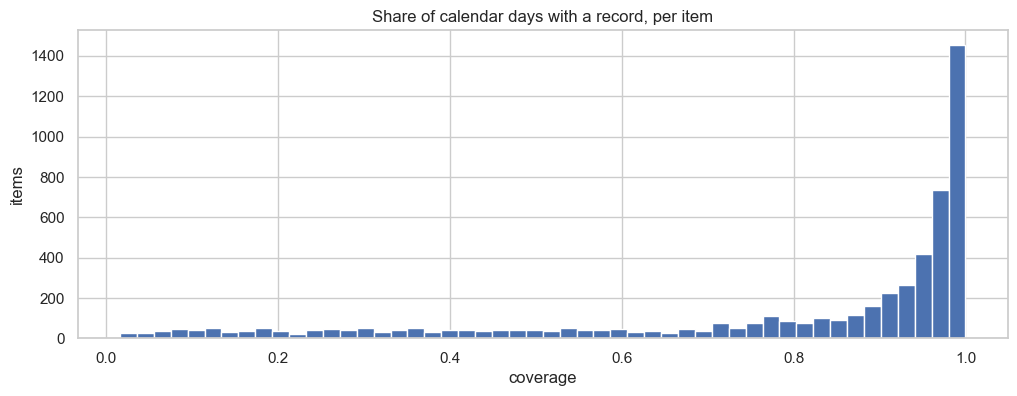

In [13]:
# How complete is each item's history? (observed days / days between first and last sale)
span = train_raw.groupby("unique_id")["date"].agg(["min", "max", "count"])
span["days"] = (span["max"] - span["min"]).dt.days + 1
span["coverage"] = span["count"] / span["days"]
display(span["coverage"].describe())
span["coverage"].hist(bins=50)
plt.title("Share of calendar days with a record, per item")
plt.xlabel("coverage"); plt.ylabel("items")
plt.show()

Next we clean the data (drop rows without `sales`, clip discounts to [0, 1], add `max_discount`) and join item info, calendar flags and weights. The code for this lives in `src/data.py`.

In [14]:
train, test = D.prepare(raw)
train = D.reduce_memory(train)
print(train.shape, test.shape)
train.head()

(4007367, 34) (47021, 32)


,unique_id,date,warehouse,total_orders,sales,sell_price_main,availability,type_0_discount,type_1_discount,type_2_discount,type_3_discount,type_4_discount,type_5_discount,type_6_discount,max_discount,product_unique_id,name,L1_category_name_en,L2_category_name_en,L3_category_name_en,L4_category_name_en,holiday_name,holiday,shops_closed,winter_school_holidays,school_holidays,weight,year,month,day,dayofweek,dayofyear,weekofyear,is_weekend
0,4845,2024-03-10,Budapest_1,6436.0,16.34,646.260010,1.00,0.00000,0.0,0.0,0.0,0.15312,0.0,0.0,0.15312,2375,Croissant_35,Bakery,Bakery_L2_18,Bakery_L3_83,Bakery_L4_1,NaN,0,0,0,0,1.925596,2024,3,10,6,70,10,1
1,4845,2021-05-25,Budapest_1,4663.0,12.63,455.959991,1.00,0.00000,0.0,0.0,0.0,0.15025,0.0,0.0,0.15025,2375,Croissant_35,Bakery,Bakery_L2_18,Bakery_L3_83,Bakery_L4_1,NaN,0,0,0,0,1.925596,2021,5,25,1,145,21,0
2,4845,2021-12-20,Budapest_1,6507.0,34.55,455.959991,1.00,0.00000,0.0,0.0,0.0,0.15025,0.0,0.0,0.15025,2375,Croissant_35,Bakery,Bakery_L2_18,Bakery_L3_83,Bakery_L4_1,NaN,0,0,0,0,1.925596,2021,12,20,0,354,51,0
3,4845,2023-04-29,Budapest_1,5463.0,34.52,646.260010,0.96,0.20024,0.0,0.0,0.0,0.15312,0.0,0.0,0.20024,2375,Croissant_35,Bakery,Bakery_L2_18,Bakery_L3_83,Bakery_L4_1,NaN,0,0,0,0,1.925596,2023,4,29,5,119,17,1
4,4845,2022-04-01,Budapest_1,5997.0,35.92,486.410004,1.00,0.00000,0.0,0.0,0.0,0.15649,0.0,0.0,0.15649,2375,Croissant_35,Bakery,Bakery_L2_18,Bakery_L3_83,Bakery_L4_1,NaN,0,0,0,0,1.925596,2022,4,1,4,91,13,0


## 4. Target variable (`sales`)

,count,mean,std,min,1%,25%,50%,75%,90%,99%,max
sales,4007367.0,108.380753,360.332735,0.0,0.0,17.98,39.52,94.47,221.79,1071.9068,26316.19


Share of zero sales: 1.23%


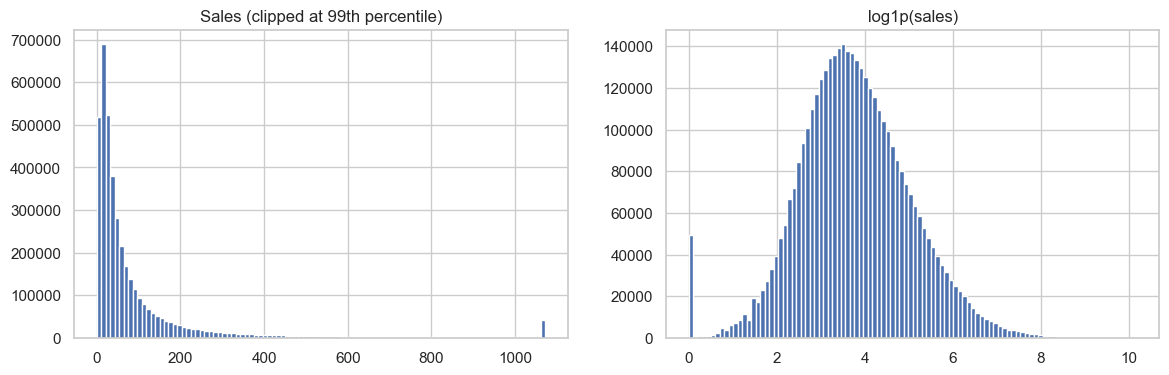

In [15]:
display(train["sales"].describe(percentiles=[.01, .25, .5, .75, .9, .99]).to_frame().T)
print(f"Share of zero sales: {(train['sales'] == 0).mean():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
train["sales"].clip(upper=train["sales"].quantile(.99)).hist(bins=100, ax=axes[0])
axes[0].set_title("Sales (clipped at 99th percentile)")
np.log1p(train["sales"]).hist(bins=100, ax=axes[1])
axes[1].set_title("log1p(sales)")
U.save_fig(fig, "01_sales_distribution")
plt.show()

## 5. Trends over time

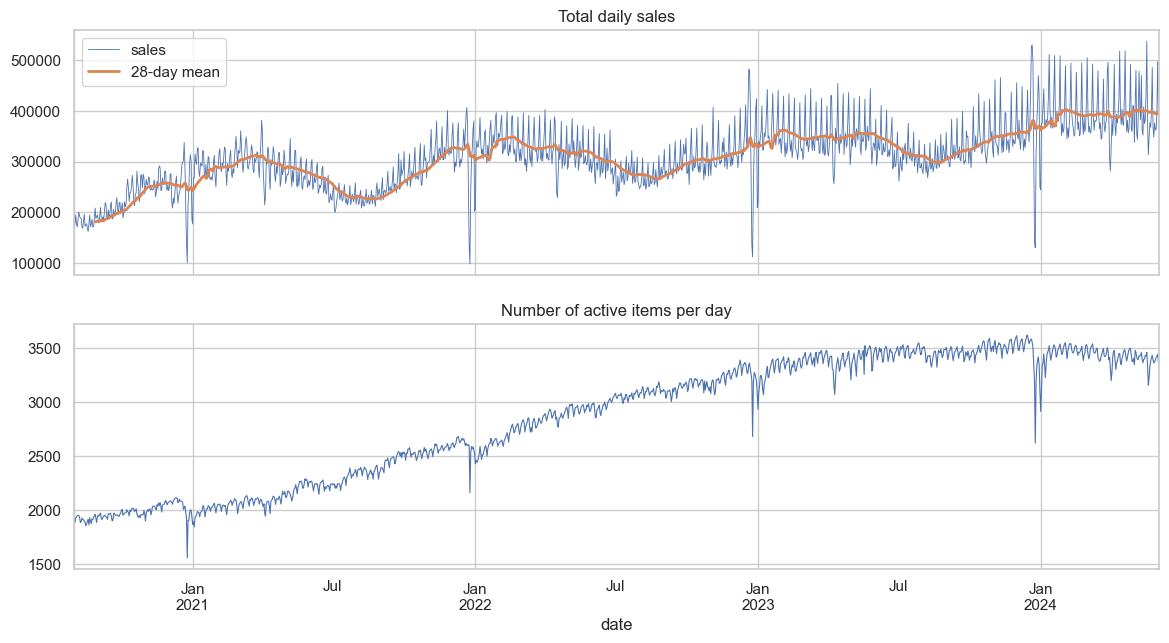

In [16]:
daily = train.groupby("date").agg(sales=("sales", "sum"), items=("unique_id", "nunique"))
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
daily["sales"].plot(ax=axes[0], lw=0.6)
daily["sales"].rolling(28).mean().plot(ax=axes[0], lw=2, label="28-day mean")
axes[0].set_title("Total daily sales"); axes[0].legend()
daily["items"].plot(ax=axes[1], lw=0.8)
axes[1].set_title("Number of active items per day")
U.save_fig(fig, "02_daily_trend")
plt.show()

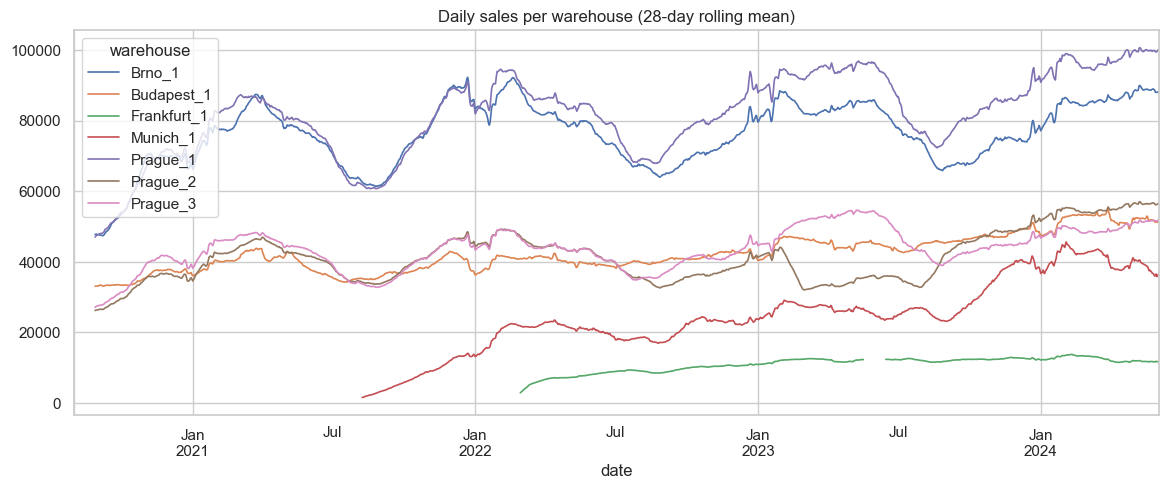

In [17]:
wh_daily = train.groupby(["date", "warehouse"])["sales"].sum().unstack()
ax = wh_daily.rolling(28).mean().plot(figsize=(14, 5), lw=1.2)
ax.set_title("Daily sales per warehouse (28-day rolling mean)")
U.save_fig(ax.figure, "03_warehouse_trend")
plt.show()

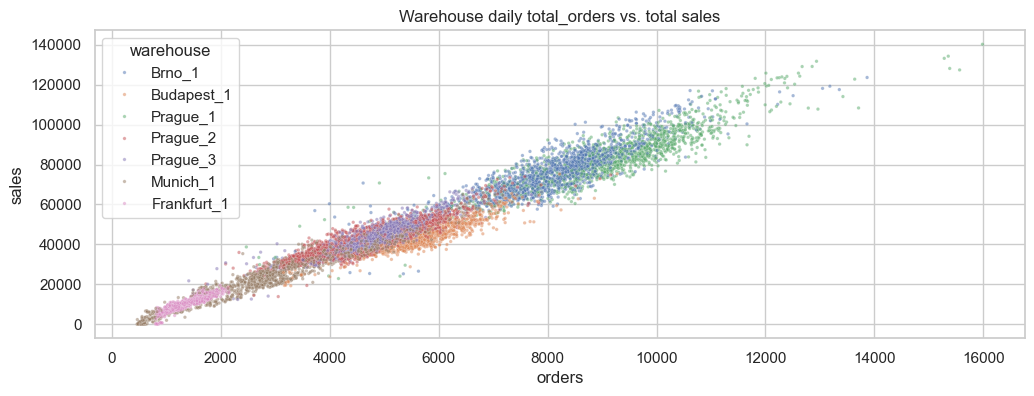

Correlation: 0.979


In [18]:
# total_orders is known in advance (also in the test set) — how does it relate to sales?
wh = train.groupby(["date", "warehouse"]).agg(sales=("sales", "sum"),
                                               orders=("total_orders", "first")).reset_index()
ax = sns.scatterplot(data=wh, x="orders", y="sales", hue="warehouse", s=6, alpha=.5)
ax.set_title("Warehouse daily total_orders vs. total sales")
plt.show()
print("Correlation:", wh[["orders", "sales"]].corr().iloc[0, 1].round(3))

## 6. Seasonality

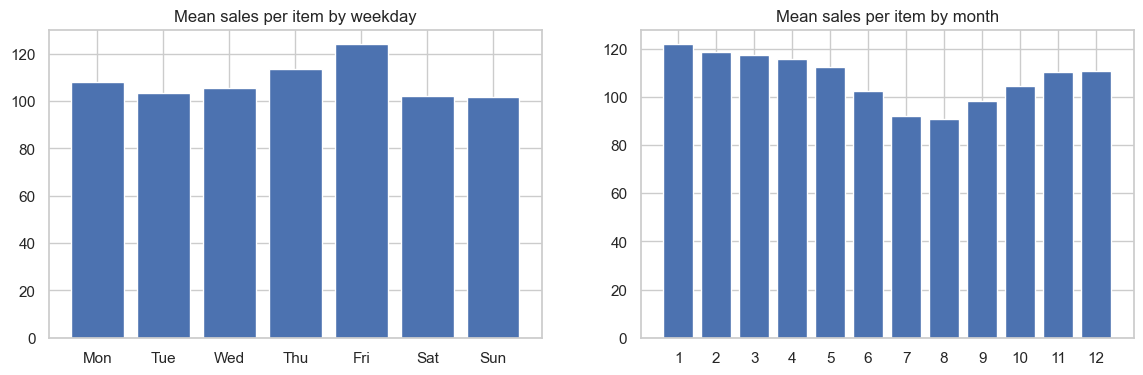

In [19]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
dow = train.groupby("dayofweek")["sales"].mean()
axes[0].bar(days, dow.values)
axes[0].set_title("Mean sales per item by weekday")
month = train.groupby("month")["sales"].mean()
axes[1].bar(month.index, month.values)
axes[1].set_title("Mean sales per item by month"); axes[1].set_xticks(range(1, 13))
U.save_fig(fig, "04_seasonality")
plt.show()

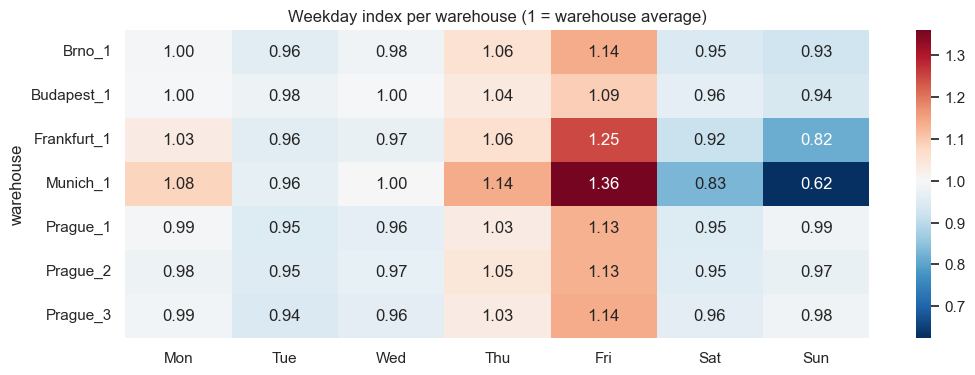

In [20]:
# weekday profile per warehouse, normalised by the warehouse mean
prof = train.pivot_table(index="warehouse", columns="dayofweek", values="sales", aggfunc="mean")
prof = prof.div(prof.mean(axis=1), axis=0)
prof.columns = days
ax = sns.heatmap(prof, annot=True, fmt=".2f", cmap="RdBu_r", center=1)
ax.set_title("Weekday index per warehouse (1 = warehouse average)")
plt.show()

## 7. Holidays and the calendar

In [21]:
for flag in D.CALENDAR_FLAGS:
    g = train.groupby(flag)["sales"].agg(["mean", "size"])
    print(f"{flag:<24} mean sales: no={g.loc[0, 'mean']:.1f}  "
          f"yes={g['mean'].get(1, np.nan):.1f}   (rows with flag: {g['size'].get(1, 0):,})")

holiday                  mean sales: no=109.1  yes=92.0   (rows with flag: 163,456)
shops_closed             mean sales: no=108.8  yes=90.5   (rows with flag: 91,225)
winter_school_holidays   mean sales: no=107.8  yes=127.7   (rows with flag: 113,443)
school_holidays          mean sales: no=108.6  yes=79.5   (rows with flag: 35,244)


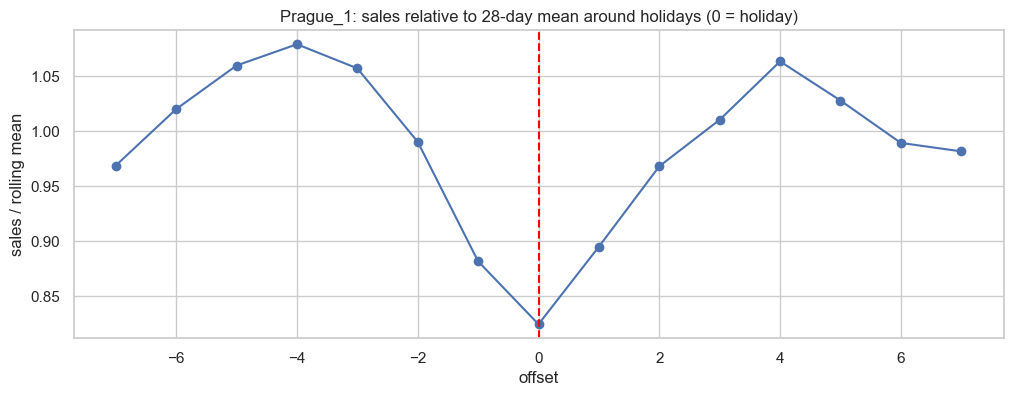

In [22]:
# daily total sales in the week around each public holiday (Prague_1 as an example)
cal = raw["calendar"]
wh_name = "Prague_1"
s = train[train["warehouse"] == wh_name].groupby("date")["sales"].sum()
hol = cal[(cal["warehouse"] == wh_name) & (cal["holiday"] == 1) &
          (cal["date"].between(s.index.min(), s.index.max()))]["date"]
rows = []
for h in hol:
    for k in range(-7, 8):
        d = h + pd.Timedelta(days=k)
        if d in s.index:
            rows.append({"offset": k, "ratio": s[d] / s.rolling(28, min_periods=7).mean().get(d, np.nan)})
eff = pd.DataFrame(rows).groupby("offset")["ratio"].mean()
ax = eff.plot(marker="o")
ax.axvline(0, color="red", ls="--")
ax.set_title(f"{wh_name}: sales relative to 28-day mean around holidays (0 = holiday)")
ax.set_ylabel("sales / rolling mean")
U.save_fig(ax.figure, "05_holiday_effect")
plt.show()

## 8. Prices and discounts

Rows with any discount: 14.61%
Share of rows where each discount type is active:


,type_0_discount,type_1_discount,type_2_discount,type_3_discount,type_4_discount,type_5_discount,type_6_discount
share,0.0362,0.0006,0.0047,0.0,0.0376,0.0023,0.0696


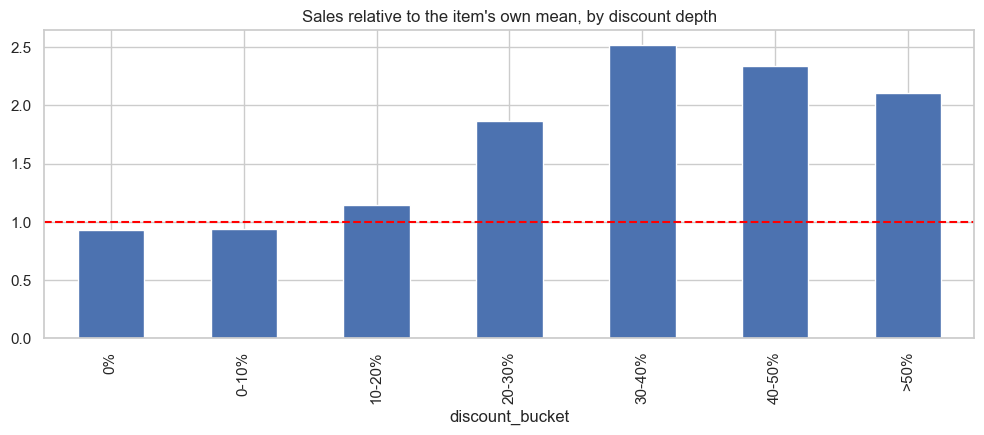

In [23]:
print(f"Rows with any discount: {(train['max_discount'] > 0).mean():.2%}")
print("Share of rows where each discount type is active:")
display((train[D.DISCOUNT_COLS] > 0).mean().round(4).to_frame("share").T)

bins = [-0.001, 0, 0.1, 0.2, 0.3, 0.4, 0.5, 1]
labels = ["0%", "0-10%", "10-20%", "20-30%", "30-40%", "40-50%", ">50%"]
train["discount_bucket"] = pd.cut(train["max_discount"], bins=bins, labels=labels)

# compare each item's sales with its own average to remove the item-size effect
item_mean = train.groupby("unique_id")["sales"].transform("mean")
train["sales_rel"] = train["sales"] / item_mean.replace(0, np.nan)
lift = train.groupby("discount_bucket", observed=True)["sales_rel"].mean()
ax = lift.plot(kind="bar")
ax.axhline(1, color="red", ls="--")
ax.set_title("Sales relative to the item's own mean, by discount depth")
U.save_fig(ax.figure, "06_discount_lift")
plt.show()

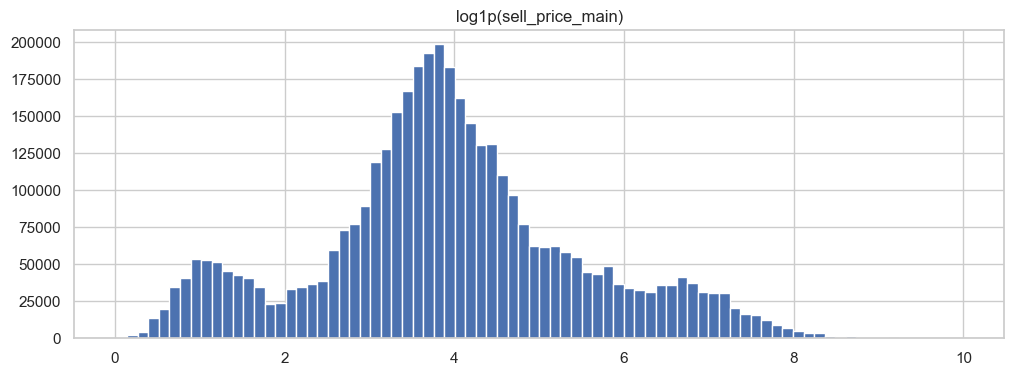

In [24]:
ax = np.log1p(train["sell_price_main"]).hist(bins=80)
ax.set_title("log1p(sell_price_main)")
plt.show()

## 9. Availability
`availability` exists only in train, so it cannot be used directly as a feature for test.

,count,mean,std,min,25%,50%,75%,max
availability,4007367.0,0.92531,0.17962,0.01,1.0,1.0,1.0,1.0


Rows with availability < 1: 24.26%


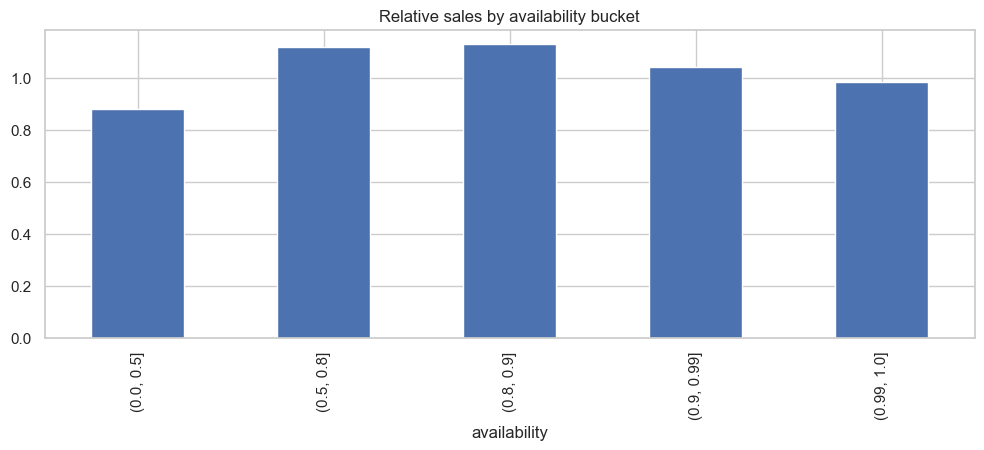

In [25]:
display(train["availability"].describe().to_frame().T)
print(f"Rows with availability < 1: {(train['availability'] < 1).mean():.2%}")
avail_bins = pd.cut(train["availability"], [0, .5, .8, .9, .99, 1.0])
ax = train.groupby(avail_bins, observed=True)["sales_rel"].mean().plot(kind="bar")
ax.set_title("Relative sales by availability bucket")
plt.show()

## 10. Product categories

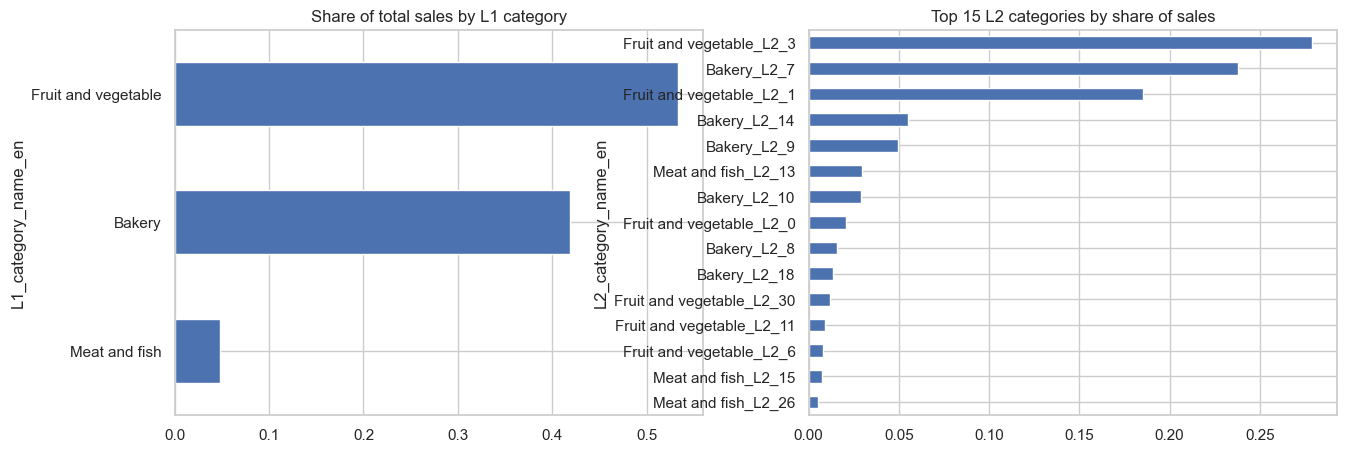

Distinct categories per level: {'L1_category_name_en': 3, 'L2_category_name_en': 47, 'L3_category_name_en': 177, 'L4_category_name_en': 68}


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
l1 = train.groupby("L1_category_name_en")["sales"].sum().sort_values()
(l1 / l1.sum()).plot(kind="barh", ax=axes[0])
axes[0].set_title("Share of total sales by L1 category")
l2 = train.groupby("L2_category_name_en")["sales"].sum().nlargest(15).sort_values()
(l2 / train["sales"].sum()).plot(kind="barh", ax=axes[1])
axes[1].set_title("Top 15 L2 categories by share of sales")
U.save_fig(fig, "07_categories")
plt.show()
print("Distinct categories per level:",
      {c: raw["inventory"][c].nunique() for c in D.CATEGORY_COLS})

## 11. Item-level behaviour and evaluation weights

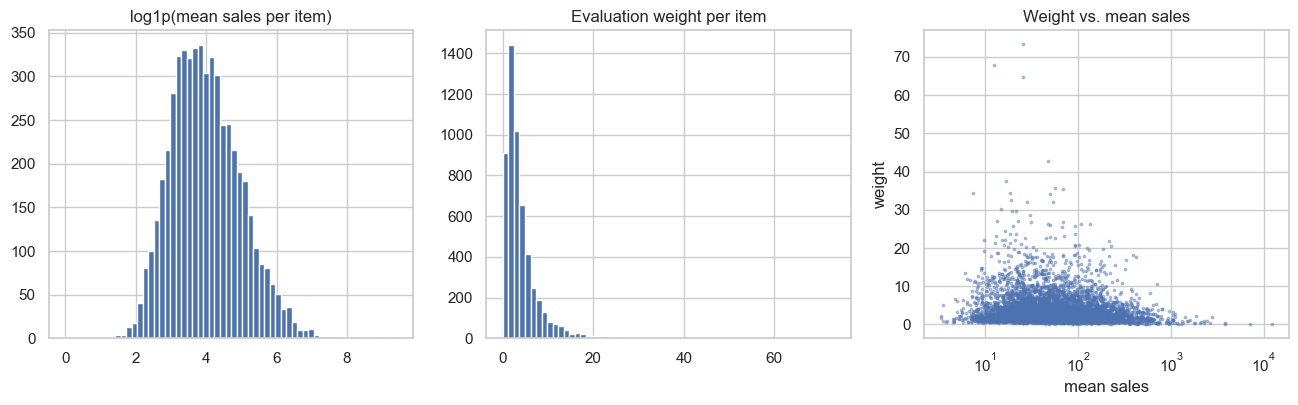

Spearman corr(weight, mean sales): -0.116


In [27]:
item = train.groupby("unique_id").agg(mean_sales=("sales", "mean"), cv=("sales", "std"),
                                      weight=("weight", "first"), n_days=("sales", "size"))
item["cv"] = item["cv"] / item["mean_sales"].replace(0, np.nan)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
np.log1p(item["mean_sales"]).hist(bins=60, ax=axes[0]); axes[0].set_title("log1p(mean sales per item)")
item["weight"].hist(bins=60, ax=axes[1]); axes[1].set_title("Evaluation weight per item")
axes[2].scatter(item["mean_sales"], item["weight"], s=3, alpha=.4)
axes[2].set_xscale("log"); axes[2].set_xlabel("mean sales"); axes[2].set_ylabel("weight")
axes[2].set_title("Weight vs. mean sales")
U.save_fig(fig, "08_items_weights")
plt.show()
print("Spearman corr(weight, mean sales):",
      item[["weight", "mean_sales"]].corr(method="spearman").iloc[0, 1].round(3))

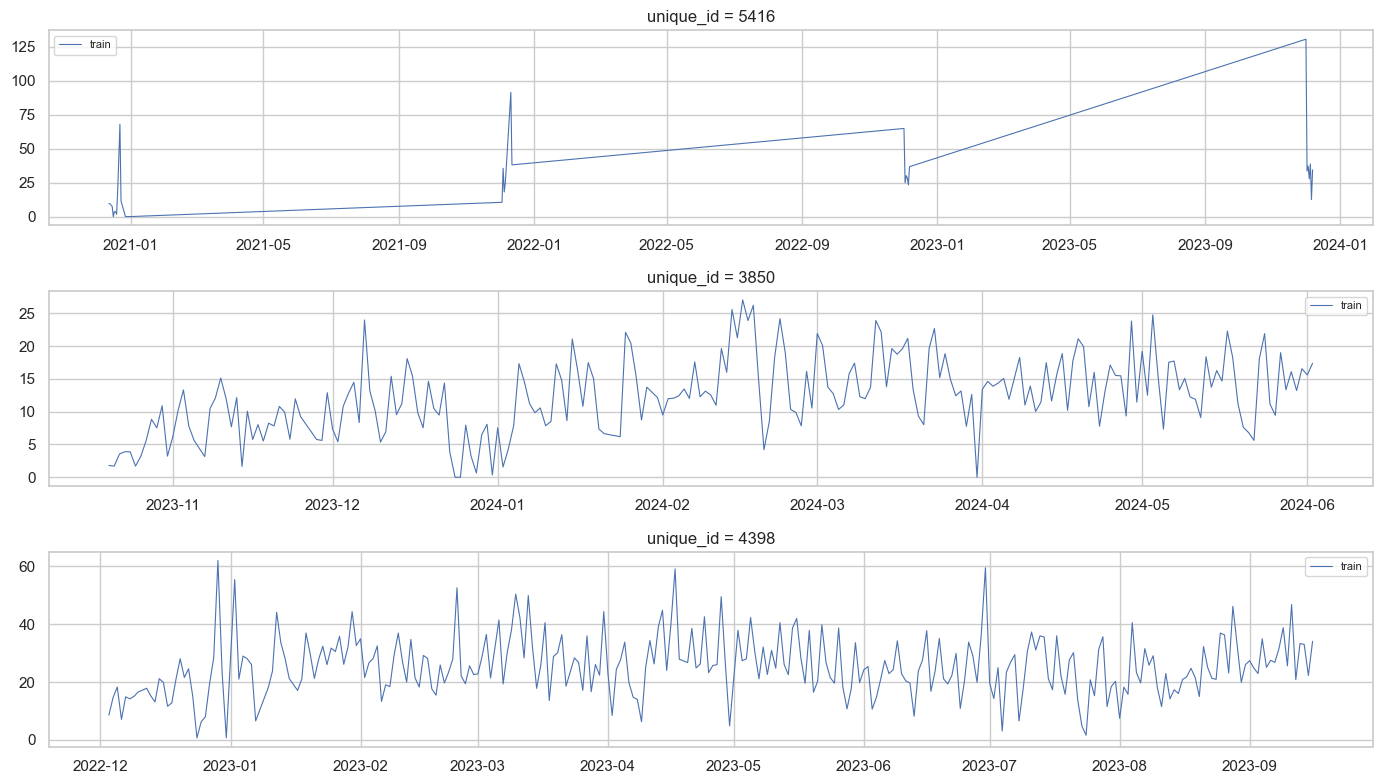

In [28]:
# a few example series
sample_ids = item.sort_values("weight", ascending=False).index[:3]
fig, axes = plt.subplots(3, 1, figsize=(14, 8))
for ax, uid in zip(axes, sample_ids):
    U.plot_item_series(train, uid, ax=ax)
plt.tight_layout()
plt.show()

## 12. Correlations

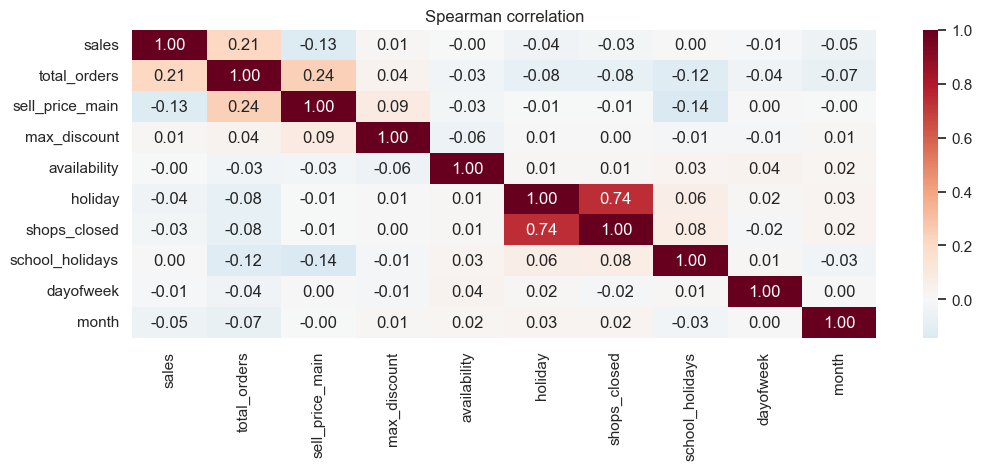

In [29]:
num_cols = ["sales", "total_orders", "sell_price_main", "max_discount", "availability",
            "holiday", "shops_closed", "school_holidays", "dayofweek", "month"]
ax = sns.heatmap(train[num_cols].corr(method="spearman"), annot=True, fmt=".2f",
                 cmap="RdBu_r", center=0)
ax.set_title("Spearman correlation")
plt.show()

## 13. Train vs. test

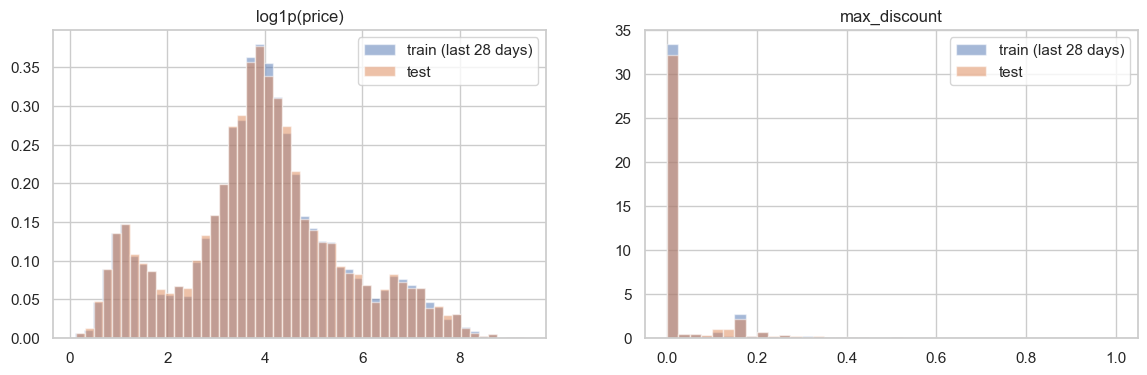

Test rows per warehouse:


warehouse,Prague_3,Prague_1,Prague_2,Brno_1,Budapest_1,Munich_1,Frankfurt_1
count,8751,8714,8655,7196,6576,3907,3222


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for df, lab in [(train[train["date"] > train["date"].max() - pd.Timedelta(days=28)], "train (last 28 days)"),
                (test, "test")]:
    axes[0].hist(np.log1p(df["sell_price_main"].dropna()), bins=50, density=True, alpha=.5, label=lab)
    axes[1].hist(df["max_discount"], bins=np.linspace(0, 1, 41), density=True, alpha=.5, label=lab)
axes[0].set_title("log1p(price)"); axes[1].set_title("max_discount")
axes[0].legend(); axes[1].legend()
plt.show()
print("Test rows per warehouse:")
display(test["warehouse"].value_counts().to_frame().T)

## 14. EDA summary
- **Size and structure.** Train has 4.0M rows: 5,390 items in 7 warehouses, from 2020-08-01 to 2024-06-02. Test covers 47k rows (3,625 items) for 2024-06-03 → 2024-06-16. Every test item has history in train, and there are no duplicate (item, date) rows.
- **Data quality.** Only 52 rows have missing `sales` / `total_orders`, and these are dropped. Some discount values are negative (down to −20.9), which is impossible, so they are clipped to [0, 1]. Item histories have gaps: the median item has a record on 94% of the days in its lifetime, but some items appear on fewer than 5% of days.
- **Target.** `sales` is very right-skewed (median 39.5, mean 108, max 26k), and only 1.2% of rows are zero. Item scale varies by orders of magnitude, so per-item statistics are essential and a log transform helps.
- **Trend.** Total daily sales almost doubled, from ~206k/day in the first 90 days to ~394k/day in the last 90 days.
- **Weekly seasonality.** Friday is the strongest day (index 114) and the weekend is the weakest (94). Thursday is also above average (105).
- **Yearly seasonality.** Sales are highest in January (113) and lowest in July–August (84–85), the summer holiday dip.
- **Warehouses.** Mean sales per item range from 46 (Frankfurt_1) to 166 (Brno_1).
- **`total_orders`.** At warehouse-day level it correlates 0.98 with total sales, and it is given for the test days, which makes it a key feature.
- **Calendar.** Holidays (92 vs 109) and shop-closure days (90.5) have lower sales, and so do school holidays (79.5). Winter school holidays are higher (128), likely because they fall in the strong January–February period.
- **Discounts.** 14.6% of rows are discounted. Relative to the item's own mean, sales rise to ×1.88 at 20–30% discount and ×2.54 at 30–40%. Small discounts (<10%) show almost no lift.
- **Availability.** 24% of rows have availability < 1. It is missing in test, so it can only be used through historical aggregates.
- **Categories.** Fruit & vegetables account for 53% of sales, Bakery for 42%, and Meat & fish for 5%. There are 47 L2 and 177 L3 categories.
- **Weights.** Weights are skewed (median 2.8, max 73). The top 10% of items carry 34% of the total weight. Weight is barely related to sales volume (Spearman −0.12), so small items can matter a lot in WMAE.

## 15. Baseline models
**Validation setup.** The last 14 days of train are held out as a validation set, mirroring the 14-day Kaggle test horizon. Every model is trained on the earlier data and scored with WMAE on that window.

| Baseline | Idea |
|---|---|
| Naive (last value) | last observed sales of the item |
| Seasonal naive | last observed sales on the same weekday |
| Moving average (7d / 28d) | mean of the last 7 / 28 days |
| Weekday mean (8w) | the item's mean per weekday over the last 8 weeks |
| Ridge regression | linear model on calendar, price, discount and item-level statistics (log target) |
| Random forest | same features, non-linear model |

All baselines are implemented in `src/models.py` with a common `fit` / `predict` interface.

In [31]:
tr, va = D.time_split(train, horizon_days=14)
print("train:", tr["date"].min().date(), "→", tr["date"].max().date(), f"({len(tr):,} rows)")
print("valid:", va["date"].min().date(), "→", va["date"].max().date(), f"({len(va):,} rows)")

train: 2020-08-01 → 2024-05-19 (3,960,048 rows)
valid: 2024-05-20 → 2024-06-02 (47,319 rows)


In [32]:
baselines = M.all_baselines(seed=42)
results, val_preds = U.evaluate_models(baselines, tr, va)
results

Naive (last value)               WMAE=42.525  (0.8s)


Seasonal naive (same weekday)    WMAE=36.079  (2.0s)
Moving average (7d)              WMAE=32.858  (0.1s)
Moving average (28d)             WMAE=30.795  (0.1s)


Weekday mean (8w)                WMAE=29.088  (0.2s)


/private/tmp/claude-501/-Users-aliosmanbulut-Downloads/4c2e93ec-e8ca-454e-9114-811365f6594b/scratchpad/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/private/tmp/claude-501/-Users-aliosmanbulut-Downloads/4c2e93ec-e8ca-454e-9114-811365f6594b/scratchpad/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/private/tmp/claude-501/-Users-aliosmanbulut-Downloads/4c2e93ec-e8ca-454e-9114-811365f6594b/scratchpad/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/private/tmp/claude-501/-Users-aliosmanbulut-Downloads/4c2e93ec-e8ca-454e-9114-811365f6594b/scratchpad/venv/lib/python3.9/site-packages/sklearn/linear_model/_ridge.py:215: LinAlgWarning: Ill-conditioned matrix (rcond=2.79268e-08): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", over

Ridge regression                 WMAE=28.640  (1.8s)


Random forest                    WMAE=25.667  (30.1s)


,model,WMAE,MAE,RMSE,seconds
0,Random forest,25.666642,31.038554,80.803734,30.1
1,Ridge regression,28.639879,38.760588,168.918377,1.8
2,Weekday mean (8w),29.087826,32.482346,102.965736,0.2
3,Moving average (28d),30.794959,34.548681,110.869095,0.1
4,Moving average (7d),32.858073,36.433945,121.331409,0.1
5,Seasonal naive (same weekday),36.079150,38.499117,119.861638,2.0
6,Naive (last value),42.524775,47.144762,139.525071,0.8


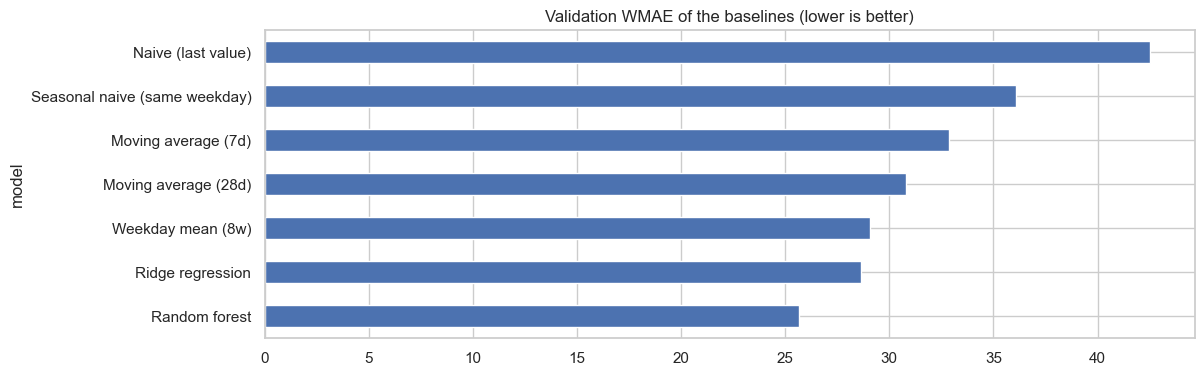

In [33]:
ax = results.set_index("model")["WMAE"].sort_values().plot(kind="barh")
ax.set_title("Validation WMAE of the baselines (lower is better)")
U.save_fig(ax.figure, "09_baseline_wmae")
plt.show()

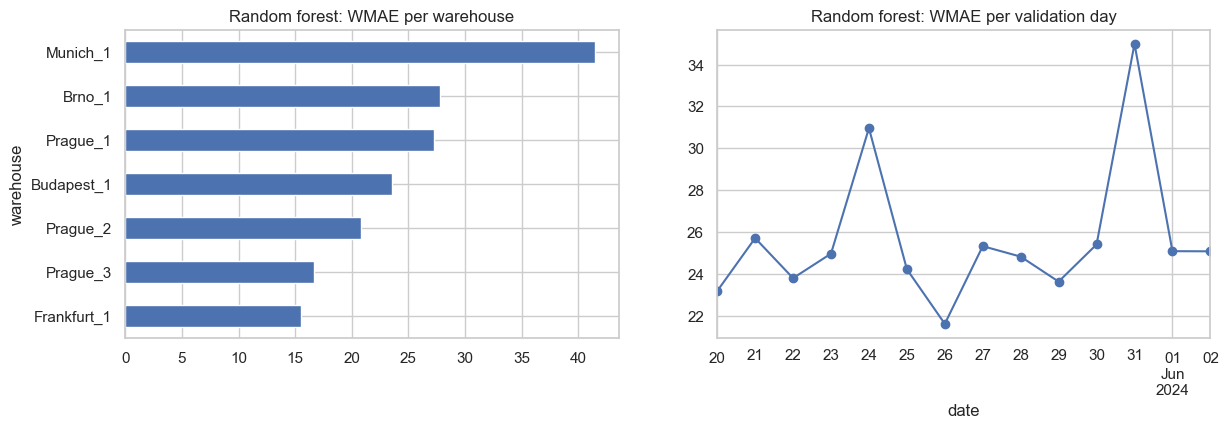

In [34]:
# where does the best baseline make its errors?
best = results.loc[0, "model"]
err = va.assign(abs_err=np.abs(va["sales"] - val_preds[best]) * va["weight"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
(err.groupby("warehouse")["abs_err"].sum() / err.groupby("warehouse")["weight"].sum()).sort_values().plot(
    kind="barh", ax=axes[0], title=f"{best}: WMAE per warehouse")
(err.groupby("date")["abs_err"].sum() / err.groupby("date")["weight"].sum()).plot(
    ax=axes[1], marker="o", title=f"{best}: WMAE per validation day")
plt.show()

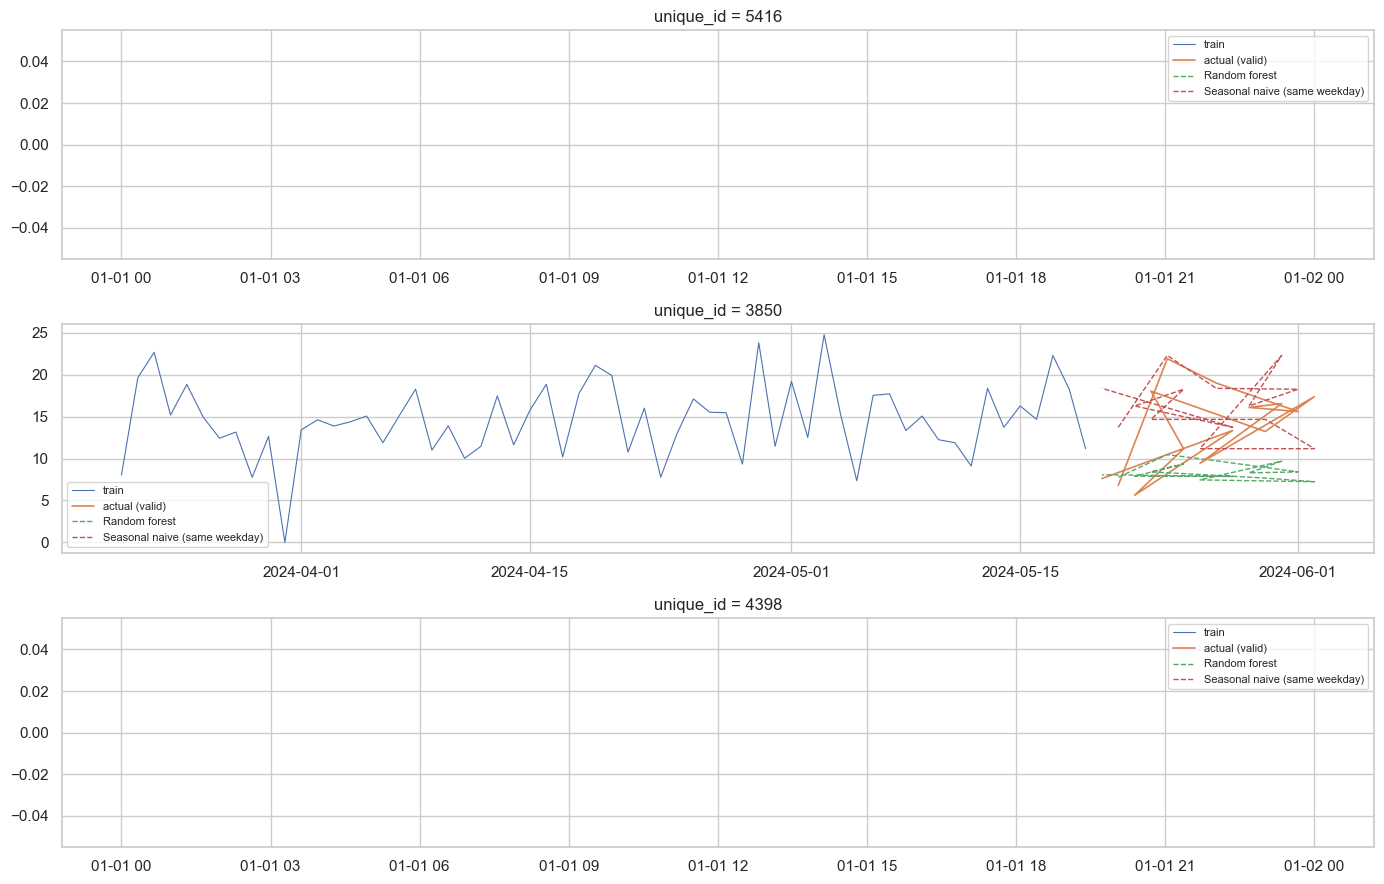

In [35]:
# predictions vs. actuals for the highest-weight items
show = {k: val_preds[k] for k in [best, "Seasonal naive (same weekday)"] if k in val_preds}
fig, axes = plt.subplots(3, 1, figsize=(14, 9))
for ax, uid in zip(axes, sample_ids):
    U.plot_item_series(tr[tr["date"] > tr["date"].max() - pd.Timedelta(days=60)], uid,
                       ax=ax, valid=va, preds=show)
plt.tight_layout()
plt.show()

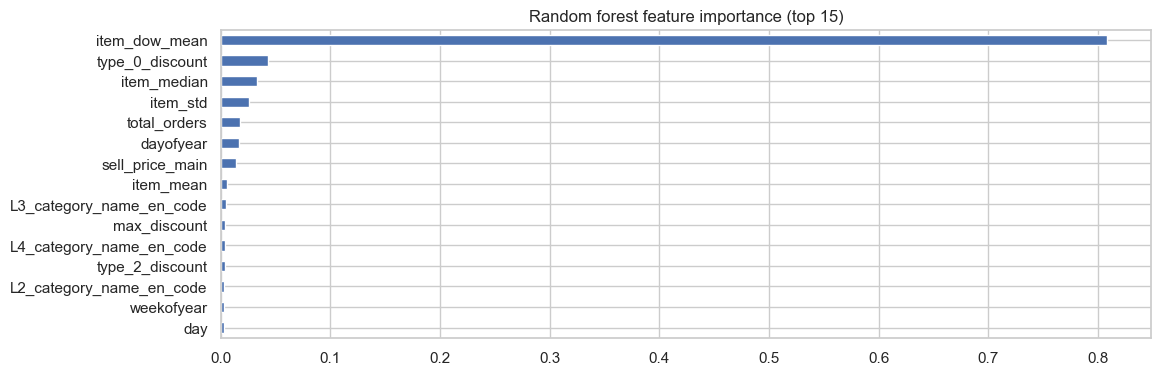

In [36]:
# which features does the random forest rely on?
rf = next(m for m in baselines if m.name == "Random forest")
imp = pd.Series(rf.estimator.feature_importances_, index=rf.feature_names_).nlargest(15).sort_values()
ax = imp.plot(kind="barh", title="Random forest feature importance (top 15)")
plt.show()

## 16. Kaggle submission
The best baseline is refitted on the full training data and used to predict the test set. The competition has ended, but late submissions are still scored. Upload the file under *Late Submission* and record the public/private scores in the README.

In [37]:
best_model = next(m for m in M.all_baselines(seed=42) if m.name == best)
best_model.fit(train)
test_pred = best_model.predict(test)
slug = best.lower().replace(" ", "_").replace("(", "").replace(")", "")
sub = U.make_submission(test, test_pred, f"submissions/a1_{slug}.csv")
sub.head()

Saved 47,021 rows to submissions/a1_random_forest.csv


,id,sales_hat
0,1226_2024-06-03,13.473349
1,1226_2024-06-11,73.140094
2,1226_2024-06-13,80.161876
3,1226_2024-06-15,61.046031
4,1226_2024-06-09,10.973852


In [38]:
# optional: submit directly from the notebook
# !kaggle competitions submit -c rohlik-sales-forecasting-challenge-v2 -f submissions/<file>.csv -m "A1 baseline"

## 17. Conclusion
**Validation WMAE (last 14 days of train):**

| Model | WMAE |
|---|---|
| Random forest | **25.67** |
| Ridge regression | 28.64 |
| Weekday mean (8w) | 29.09 |
| Moving average (28d) | 30.79 |
| Moving average (7d) | 32.86 |
| Seasonal naive | 36.08 |
| Naive (last value) | 42.52 |

*(See the results table above for the exact numbers of the current run.)*

- **Smoothing helps.** Simple averages beat single-value naive forecasts, because daily sales are noisy. Using the weekday profile improves things further, as the weekly seasonality suggested.
- **Features help.** The random forest is the best baseline (≈40% better than the last-value naive). It uses the known-in-advance information (`total_orders`, price, discounts, calendar) on top of the item statistics.

**Ideas for Assignment 2:**
- lag and rolling-window features computed without leakage
- price and discount features relative to the item's usual level
- gradient boosting (LightGBM / XGBoost) trained with the evaluation weights
- a direct multi-horizon setup and ensembling